# Práctica 1 · Regresión lineal simple y múltiple

Objetivo: vincular mínimos cuadrados, código e interpretación. Recorrido básico y extensiones. Ejecute todas las celdas en orden. La prueba permanece reservada; los resultados mostrados son de validación.

**Fuentes:** Géron, 3.ª ed., caps. 2–5; Grus, 2.ª ed., caps. 13–16; Gallatin y Albon, Cookbook adjunto, caps. 3–6 (preprocesamiento). Las consignas y los datos sintéticos son elaboración didáctica. Véase `../apuntes.md` y `../datos/README.md`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
ROOT = Path.cwd()
if not (ROOT / 'datos').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'datos').is_dir():
    raise FileNotFoundError('Abra el notebook desde la carpeta del subtema o desde notebooks, conservando datos/.')
print('Versiones:', sklearn.__version__, np.__version__, pd.__version__)

Versiones: 1.8.0 2.3.5 2.2.3


## 1. Cálculo desde cero
Tabla sintética de cinco ejemplos. Los errores siguientes son de ajuste, no prueba de generalización.

In [2]:
x = np.array([1, 2, 3, 4, 5.])
y = np.array([3, 4, 6, 8, 9.])
b = ((x-x.mean())*(y-y.mean())).sum() / ((x-x.mean())**2).sum()
a = y.mean() - b*x.mean()
pred = a+b*x
mae = np.abs(y-pred).mean()
rmse = np.sqrt(((y-pred)**2).mean())
r2 = 1-((y-pred)**2).sum()/((y-y.mean())**2).sum()
print('Intercepto y pendiente:', a, b)
print(pd.DataFrame({'x':x, 'y':y, 'pred':pred, 'residuo':y-pred}).to_string(index=False))
print('MAE, RMSE, R²:', mae, rmse, r2)
from sklearn.linear_model import LinearRegression
m = LinearRegression().fit(x[:,None],y)
print('scikit-learn:', m.intercept_, m.coef_)

Intercepto y pendiente: 1.1999999999999993 1.6
  x   y  pred  residuo
1.0 3.0   2.8      0.2
2.0 4.0   4.4     -0.4
3.0 6.0   6.0      0.0
4.0 8.0   7.6      0.4
5.0 9.0   9.2     -0.2
MAE, RMSE, R²: 0.23999999999999994 0.28284271247461895 0.9846153846153847
scikit-learn: 1.1999999999999993 [1.6]


**Ejercicio P1-A.** Calcule a mano la predicción para 6 horas. ¿Es interpolación o extrapolación? ¿Qué evidencia falta para confiar en ella?

## 2. Comparación en validación
Consumo sintético con tres entradas. DummyRegressor aprende una referencia a partir de entrenamiento.

                modelo  MAE_kwh  RMSE_kwh      R2
Media de entrenamiento   4.0460    4.7545 -0.0170
         Lineal simple   1.2259    1.4841  0.9009
       Lineal múltiple   0.9041    1.1246  0.9431
Intercepto: 2.7515383873522126
Coeficientes: {'horas': np.float64(1.7955769157094759), 'carga': np.float64(4.307784420796547), 'temperatura': np.float64(0.08218398383662165)}


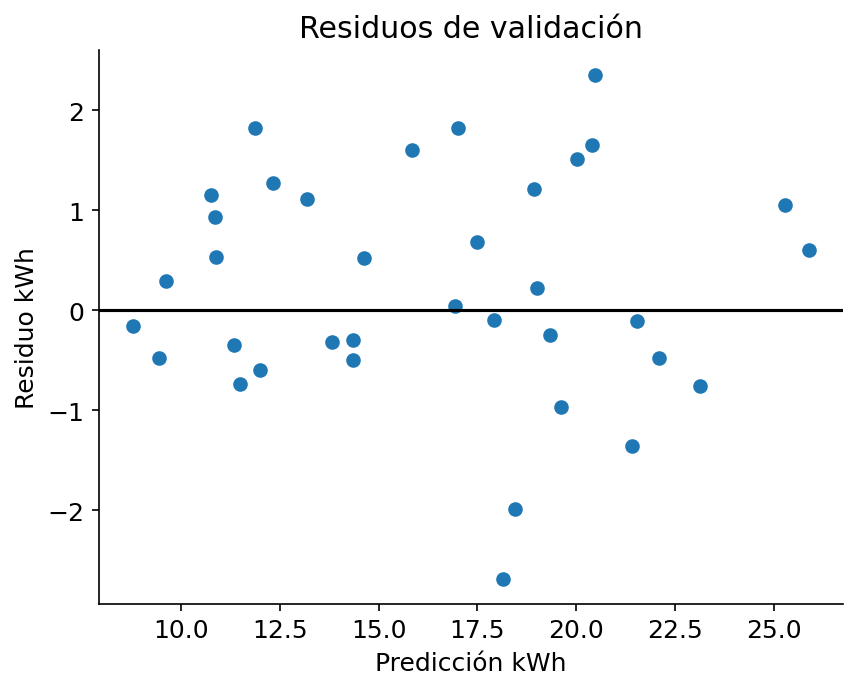

In [3]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
df = pd.read_csv(ROOT/'datos/consumo-sintetico.csv')
tr = df[df.particion=='entrenamiento']; va = df[df.particion=='validacion']
features = ['horas','carga','temperatura']; yt = tr.consumo_kwh; yv = va.consumo_kwh
rows=[]; models={}
for name, model, cols in [
 ('Media de entrenamiento',DummyRegressor(strategy='mean'),features),
 ('Lineal simple',LinearRegression(),['horas']),
 ('Lineal múltiple',LinearRegression(),features)]:
    model.fit(tr[cols],yt); yp=model.predict(va[cols]); models[name]=(model,cols)
    rows.append({'modelo':name,'MAE_kwh':mean_absolute_error(yv,yp),
                 'RMSE_kwh':np.sqrt(mean_squared_error(yv,yp)),'R2':r2_score(yv,yp)})
print(pd.DataFrame(rows).round(4).to_string(index=False))
model,cols=models['Lineal múltiple']
print('Intercepto:',model.intercept_)
print('Coeficientes:',dict(zip(cols,model.coef_)))
yp=model.predict(va[cols]); plt.scatter(yp,yv-yp);plt.axhline(0,color='black');plt.xlabel('Predicción kWh');plt.ylabel('Residuo kWh');plt.title('Residuos de validación');plt.show()

## 3. Sensibilidad a un valor atípico
Alteramos solo una etiqueta de entrenamiento. Nunca modifique validación para facilitar el ajuste.

In [4]:
yt_bad=yt.copy();yt_bad.iloc[0]+=60
bad=LinearRegression().fit(tr[features],yt_bad)
print('MAE original:',mean_absolute_error(yv,model.predict(va[features])))
print('MAE con etiqueta alterada:',mean_absolute_error(yv,bad.predict(va[features])))

MAE original: 0.9040897595657156
MAE con etiqueta alterada: 1.0954349727416786


**Entregable:** interprete MAE y RMSE con unidades, compare con la referencia y explique por qué los coeficientes aprendidos no demuestran causalidad.

**Extensión P1-B:** añada una columna aleatoria únicamente como característica y repita la comparación. ¿Mejora en validación? Conserve la semilla, documente la decisión y no consulte prueba.